# 03 文本长度规范、RNN变体与人名分类数据准备

本篇对应 **day03**，保存在「黑马程序员 → AI大模型开发 → 07-NLP自然语言处理」。承接02的句长分析与词向量，先统一文本长度，再理解RNN、LSTM、Bi-LSTM、GRU，最后把变长人名整理成可送入模型的批次。

资料：[2026最新版NLP自然语言处理](https://pan.baidu.com/s/16JhWSR5VZu0tEQ0EcRJBwA?pwd=1234)，提取码 `1234`。已核对 `03-视频/day03` 的 **19节标题**，在线阅读《03-文本预处理-下》第31–38页、《04-RNN及其变体》全部46页、《05-RNN案例人名分类器》第1–22页。本篇案例使用第1–17页的数据准备范围；从模型构建到训练、预测留给后续笔记。

视频未逐段转录，未取得课程原代码、原始人名数据和本地PDF。本篇说明、Python示例、小样本和7幅教学图均独立编写，示例结果不能当作课程原实验成绩。沿用前两篇格式：**全部为Markdown单元；Python代码块按顺序复制到代码单元即可运行；所有图片直接嵌入Notebook附件。**

## 本篇学习路线

| day03视频 | 主题 | 学完应能完成 |
| --- | --- | --- |
| 01 | 文本长度规范 | 区分截断方向、补齐方向、真实长度与mask |
| 02 | 回译增强 | 解释流程，检查语义与标签，避免数据泄漏 |
| 03–08 | 传统RNN | 写出递推式，读懂T/B/I/H/L/D，核对output与hn |
| 09–12 | LSTM、Bi-LSTM | 区分隐藏状态与细胞状态，正确取双向最终表示 |
| 13–14 | GRU | 理解两类门，区分课件与PyTorch的更新门约定 |
| 15–19 | 人名分类数据准备 | TSV → 字符one-hot → Dataset → DataLoader |

本篇终点是**数据接口与前向一致性检查**。分类头、损失、训练循环及准确率对比需要另行构建，不能凭随机初始化的输出评价模型效果。


## 1. 环境与运行约定

代码只依赖Python、NumPy和PyTorch，不需要TensorFlow、翻译API、jieba或课程外部数据。CPU即可完成；固定随机种子便于复查本篇数值，换版本或设备时末位浮点数可能不同。

```bash
python -m pip install numpy torch
```

```python
import io
import json
import numbers
import platform
import string
import tempfile
import unicodedata
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

torch.manual_seed(2026)
torch.set_num_threads(2)
DEVICE = torch.device("cpu")
print("Python:", platform.python_version())
print("NumPy:", np.__version__, "PyTorch:", torch.__version__, "device:", DEVICE)
```

本篇不在笔记目录写入数据或模型。TSV与配置保存示例只使用自动清理的系统临时目录；图已经内嵌，阅读时无需额外下载。


## 2. 文本长度规范：截断与padding是两个选择

上一篇分析长度分布，本篇决定怎样把不同长度的序列放进同一个张量。文本要先按任务切成token，再依据**token长度**定上限；不能把字符数的p95直接当作词或子词的p95。

- **截断（truncating）**：超过上限时删去一部分。`pre`删开头、保留末尾；`post`删末尾、保留开头。
- **补齐（padding）**：不足上限时加入占位。`pre`在左边补，`post`在右边补。
- **真实长度（lengths）**：截断之后、补齐之前的有效token数量。
- **mask**：哪些位置属于真实序列。它不会仅凭存在就自动影响模型，必须传入使用mask的运算，或采用packed sequence等处理方式。

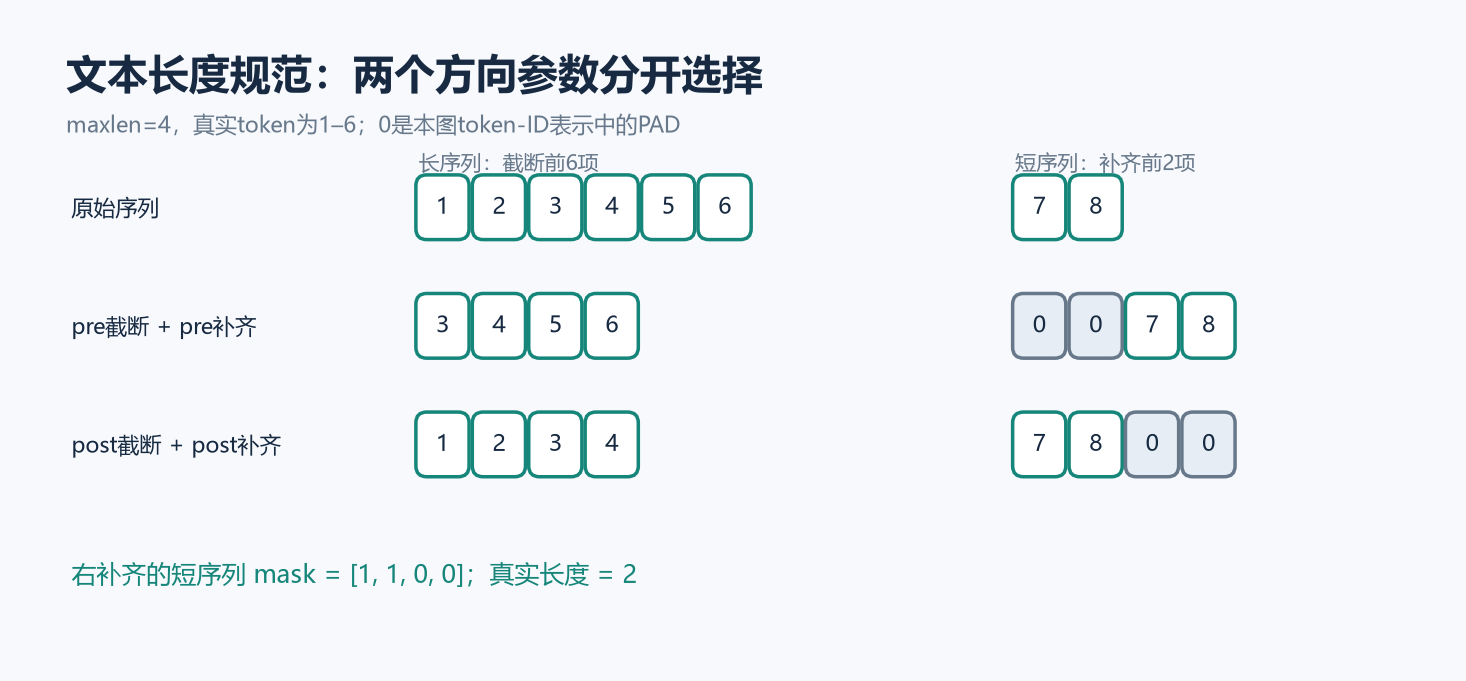

课件样例调用 `pad_sequences(sequences=x_train, maxlen=10)`，没有显式指定方向。**Keras的默认padding与truncating都是pre**，因此输出保留长序列最后10项，短序列在左边补零。课件旁边提到的`post`选项不能当作这次调用的实际参数。

| 策略 | 适用考虑 | 需要检查 |
| --- | --- | --- |
| 固定全局上限 | shape稳定，便于估算资源 | 长文本信息丢失率、短文本补齐比例 |
| 每批最长长度 | 通常减少padding计算 | 不同批次T不同，需要正确取真实末尾 |
| 按长度分桶 | 长度相近的样本成批 | 随机性、训练顺序及实现复杂度 |

上限只依据训练数据与资源预算确定。课件提到约90%覆盖率，可当作起点；应检查被截掉的是否正好是结论、否定或关键实体，不能把某个分位数视为普遍最佳答案。


## 3. 用NumPy明确实现四种方向组合

下例处理一维正整数token ID，约定 `0=PAD`。返回mask时依据有效位置，而非猜测非零元素；空序列可以表示成全PAD，但后文的packed RNN会拒绝长度为0的样本。

```python
def pad_token_ids(sequences, maxlen, *, padding="post", truncating="post"):
    if isinstance(maxlen, bool) or not isinstance(maxlen, numbers.Integral) or maxlen <= 0:
        raise ValueError("maxlen必须是正整数")
    if padding not in {"pre", "post"} or truncating not in {"pre", "post"}:
        raise ValueError("方向只能是pre或post")
    sequences = [list(seq) for seq in sequences]
    values = np.zeros((len(sequences), maxlen), dtype=np.int64)
    mask = np.zeros_like(values, dtype=bool)
    lengths = np.zeros(len(sequences), dtype=np.int64)
    for row, seq in enumerate(sequences):
        if any(isinstance(v, bool) or not isinstance(v, numbers.Integral) or v <= 0 for v in seq):
            raise ValueError("真实token ID必须为正整数，0留给PAD")
        kept = seq[-maxlen:] if truncating == "pre" else seq[:maxlen]
        size = len(kept)
        lengths[row] = size
        if size:
            start = maxlen - size if padding == "pre" else 0
            values[row, start:start + size] = kept
            mask[row, start:start + size] = True
    return values, lengths, mask

x_train = [
    [1, 23, 5, 32, 55, 63, 2, 21, 78, 32, 23, 1],
    [2, 32, 1, 23, 1],
]
pre_ids, pre_lengths, pre_mask = pad_token_ids(x_train, 10, padding="pre", truncating="pre")
post_ids, post_lengths, post_mask = pad_token_ids(x_train, 10)
assert pre_ids.tolist() == [
    [5, 32, 55, 63, 2, 21, 78, 32, 23, 1],
    [0, 0, 0, 0, 0, 2, 32, 1, 23, 1],
]
assert post_ids.tolist() == [
    [1, 23, 5, 32, 55, 63, 2, 21, 78, 32],
    [2, 32, 1, 23, 1, 0, 0, 0, 0, 0],
]
for p in ("pre", "post"):
    for t in ("pre", "post"):
        ids, lengths, mask = pad_token_ids([[1, 2, 3, 4], [5], []], 3, padding=p, truncating=t)
        assert lengths.tolist() == [3, 1, 0]
        assert np.array_equal(mask.sum(axis=1), lengths)
        assert np.all(ids[~mask] == 0)
assert pad_token_ids([], 3)[0].shape == (0, 3)
print("pre/pre:\n", pre_ids)
print("post/post:\n", post_ids)
print("真实长度:", post_lengths.tolist())
```

Keras也可以显式写 `padding="post", truncating="post"`。这段NumPy示例仅复现本篇整数序列场景，不宣称支持Keras全部参数、dtype和多维输入。

**右补齐适合本篇packed sequence流程。** 左padding的有效序列从中间开始，不能把整个张量和lengths直接交给默认从第0位置消费的packing操作。


## 4. 回译增强：形式变化之后还要检查标签

回译流程：原语言文本 → 中间语言译文 → 原语言新表达。其目的是获得表达不同、含义尽量一致的候选样本；并不是所有回译结果都天然保留原标签。

重点检查否定、程度、转折、实体、金额、日期、专有词和歧义。例如“并非完全不能用”被翻成“不能用”，或“最多退款100元”变成“至少退款100元”，都会影响任务语义。标签复用需要审核，不能只看句子通顺。

**先划分数据，再只增强训练集。** 原句及其增强版本要属于同一组；验证集、测试集保持独立，不能让原句在训练集、近似改写在测试集。真实项目还应按用户、来源或文档组划分。

下面是**手工编写的离线流程示意**，不是翻译模型的输出，也没有调用外部API。`reviewed`表示示例中的人工审核标记，实际工作不能靠硬编码字符串判断语义。

```python
offline_candidates = [
    {"source_id": "train-1", "original": "这款耳机不错，声音清楚。", "label": 1,
     "bridge": "These headphones are good and the sound is clear.",
     "candidate": "这副耳机挺好，音质清晰。", "reviewed": True},
    {"source_id": "train-2", "original": "我不喜欢这款耳机。", "label": 0,
     "bridge": "I do not like these headphones.",
     "candidate": "我喜欢这款耳机。", "reviewed": False},
]
original_train = [(r["source_id"], r["original"], r["label"]) for r in offline_candidates]
accepted_augments = [(r["source_id"], r["candidate"], r["label"])
                     for r in offline_candidates if r["reviewed"]]
assert len(accepted_augments) == 1
assert {r[0] for r in accepted_augments} <= {r[0] for r in original_train}
print("保留候选:", accepted_augments)
print("拒绝候选:", [r["candidate"] for r in offline_candidates if not r["reviewed"]])
```

课件给出旧式翻译HTTP接口示例；服务、鉴权和返回格式可能变化，本篇不复用旧端点。若真正接入翻译服务，应单独处理额度、失败重试、重复检测和人工抽查，并用原始验证集衡量增强是否有效。


## 5. RNN：按时间传递隐藏状态

RNN（Recurrent Neural Network，循环神经网络）适合描述序列。每一步读入当前特征与上一步隐藏状态，得到新的隐藏状态，使前面出现的信息有机会影响后面的表示。

“循环”是**状态递推与时间步共享参数**，不是Python代码必须写成循环，也不是输入和输出在业务上完全相同。`nn.RNN`返回隐藏表示；输出词、类别或概率需要任务对应的输出层。

| 输入/输出关系 | 例子 | 读法 |
| --- | --- | --- |
| N → 1 | 句子情感分类、人名类别分类 | 编码序列，汇总为一个判断 |
| N → N，位置对齐 | 序列标注 | 每个输入位置产生对应预测 |
| 1 → N | 图像特征条件下生成描述 | 一个条件指导序列生成 |
| N → M，长度可不同 | 翻译、摘要 | 编码输入，再解码输出 |

这是一种任务结构分类。另一个角度是单元类型（普通RNN/LSTM/GRU）、方向（单向/双向）和深度（单层/多层）。一套`nn.RNN`不会自动完成上述所有任务，解码、对齐、分类头等还要设计。


## 6. 传统RNN的递推公式与时间展开

默认tanh单元可写为：

$$
h_t=\tanh(W_{ih}x_t+b_{ih}+W_{hh}h_{t-1}+b_{hh}).
$$

其中 $x_t\in\mathbb{R}^{I}$、$h_t\in\mathbb{R}^{H}$、$W_{ih}\in\mathbb{R}^{H\times I}$、$W_{hh}\in\mathbb{R}^{H\times H}$。批量实现采用行向量，代码对应 `x_t @ W_ih.T`。

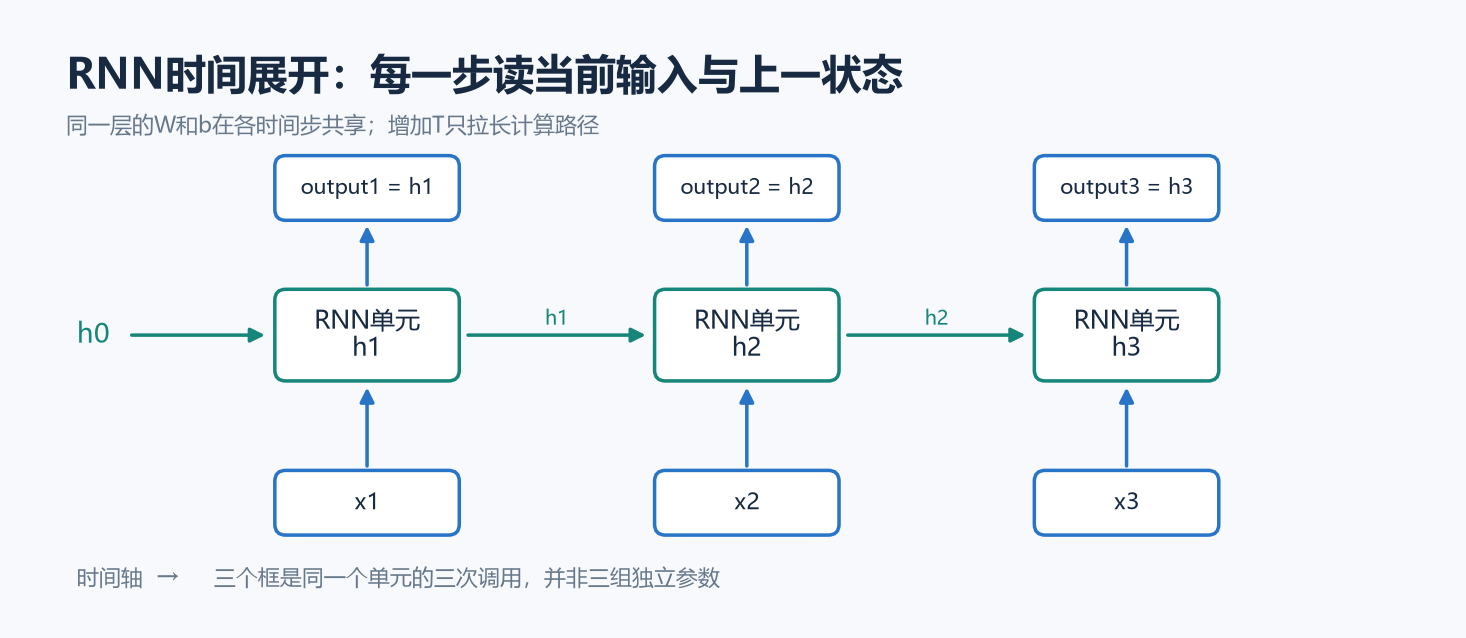

同一层在每个时间步使用同一组参数，因此**T变长不会增加该层的参数量**，却会增加计算量、状态记录及反向传播路径。多层则为每层增加自己的参数；第2层在每个位置接收第1层的输出。

初始状态可以设为0；也可以在明确的连续流任务中传递前一段状态。人名分类的不同样本互相独立，本篇每次前向从各样本的零状态开始，不能把上一个人的状态带给下一个人。


## 7. 先记住shape里的六个字母

| 符号 | 含义 | 本篇基础例子 |
| --- | --- | --- |
| T | 时间长度、序列位置数 | 4 |
| B | batch size、批大小 | 2 |
| I | 每步输入特征维度、input_size | 3 |
| H | 每个方向的隐藏维度、hidden_size | 6 |
| L | 堆叠层数、num_layers | 1 |
| D | 方向数 | 单向1，双向2 |

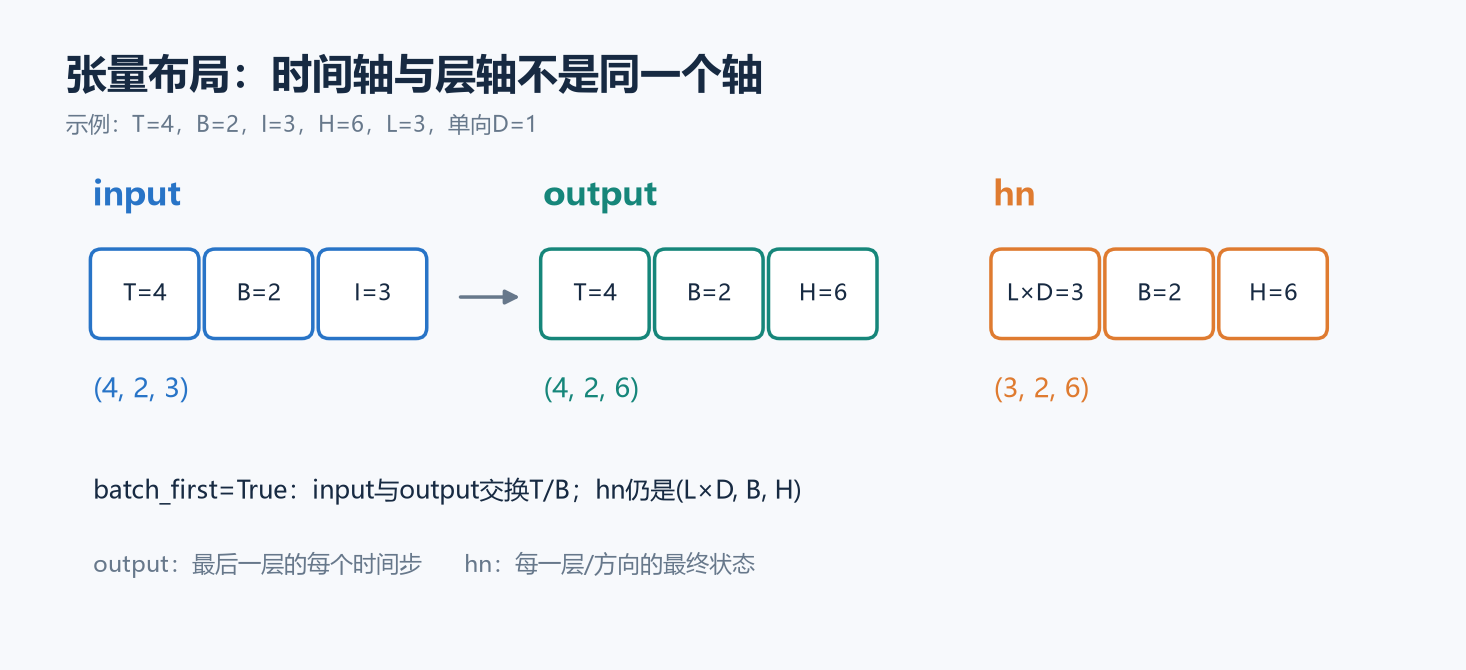

| 张量 | `batch_first=False` | `batch_first=True` |
| --- | --- | --- |
| input | `(T,B,I)` | `(B,T,I)` |
| output | `(T,B,D*H)` | `(B,T,D*H)` |
| h0、hn | `(L*D,B,H)` | **仍为`(L*D,B,H)`** |
| LSTM的c0、cn | `(L*D,B,H)` | **仍为`(L*D,B,H)`** |

这里讨论有batch维的输入，LSTM未使用projection。`output`包含**最后一层**各时间位置的表示；`hn`包含**每一层、每个方向**处理完整序列后的状态。L与T是不同轴。

`input_size`是每步向量的维数，不是句长、词表大小或类别数；只有本篇使用57维字符one-hot时，它才恰好等于字符表大小。


## 8. RNN基础API：一次读完整段序列

课件用`input_size=3, hidden_size=6`演示。它们只是形状示例；随机浮点数不是实际句子，前向输出也不是已训练的语义向量。

```python
T, B, I, H = 4, 2, 3, 6
x = torch.randn(T, B, I, device=DEVICE)
rnn = nn.RNN(input_size=I, hidden_size=H, num_layers=1).to(DEVICE)
h0 = torch.zeros(1, B, H, device=DEVICE)
output, hn = rnn(x, h0)
assert output.shape == (T, B, H)
assert hn.shape == (1, B, H)
torch.testing.assert_close(output[-1], hn[-1])
print("input:", tuple(x.shape))
print("output:", tuple(output.shape), "hn:", tuple(hn.shape))
```

不传h0时，PyTorch会按模型的层数、方向数、batch大小和dtype/device创建零初始状态。显式传入有利于理解shape。

课件个别文字把最后维写成“66”，这里的hidden_size是6，单向output最后维为6。也不能说整个output与hn相同：**仅在当前单向、无padding、完整序列设置下，最后时间步与最后层的最终状态对应。**


## 9. 改句长与改层数：观察不同轴

```python
same_rnn_parameter_count = sum(p.numel() for p in rnn.parameters())
length_shapes = {}
for current_t in (1, 4, 7):
    out_t, final_t = rnn(torch.randn(current_t, B, I))
    length_shapes[current_t] = (tuple(out_t.shape), tuple(final_t.shape))
    assert sum(p.numel() for p in rnn.parameters()) == same_rnn_parameter_count
    torch.testing.assert_close(out_t[-1], final_t[-1])

deep_rnn = nn.RNN(I, H, num_layers=3)
deep_output, deep_hn = deep_rnn(x, torch.zeros(3, B, H))
assert deep_output.shape == (T, B, H)
assert deep_hn.shape == (3, B, H)
torch.testing.assert_close(deep_output[-1], deep_hn[-1])
print("不同T:", length_shapes)
print("3层output/hn:", tuple(deep_output.shape), tuple(deep_hn.shape))
```

结论：T从4到7使output的时间轴变长，hn的shape不变；L从1到3使hn的层轴变长，output仍只返回最后一层。改变输入内容或长度会改变hn的**值**，不能因为shape相同就说状态相同。

`num_layers=3`不是“把长度设成3”。隐藏维H也不是类别数，预测18类需要另外增加从隐藏表示到18维logits的分类层。


## 10. batch_first只改变输入与output的布局

用同一组权重比较两种布局，才能判断数值是否一致；单独创建两个随机模型后比较输出没有意义。

```python
rnn_batch = nn.RNN(I, H, batch_first=True)
rnn_batch.load_state_dict(rnn.state_dict())
x_batch = x.transpose(0, 1).contiguous()
output_batch, hn_batch = rnn_batch(x_batch, h0)
torch.testing.assert_close(output_batch, output.transpose(0, 1))
torch.testing.assert_close(hn_batch, hn)
assert output_batch.shape == (B, T, H)
assert hn_batch.shape == (1, B, H)
torch.testing.assert_close(output_batch[:, -1], hn_batch[-1])
print("batch_first的input/output/hn:",
      tuple(x_batch.shape), tuple(output_batch.shape), tuple(hn_batch.shape))
```

`hn[-1]`沿层/方向轴取值，`output_batch[:, -1]`沿时间轴取值。本例二者相等，但存在padding或双向结构时不能无条件套用，后面会分别验证。


## 11. 手算一步，并核对“逐步调用=整段调用”

按PyTorch的两个bias展开公式，既验证公式，也验证时间状态确实在递推。本例用float64减少数值误差。

```python
manual_rnn = nn.RNN(I, H).double()
manual_x = x.double()
manual_h0 = torch.zeros(1, B, H, dtype=torch.float64)
with torch.no_grad():
    whole_out, whole_hn = manual_rnn(manual_x, manual_h0)
    state = manual_h0[0]
    manual_states = []
    for xt in manual_x:
        state = torch.tanh(
            xt @ manual_rnn.weight_ih_l0.T + manual_rnn.bias_ih_l0
            + state @ manual_rnn.weight_hh_l0.T + manual_rnn.bias_hh_l0
        )
        manual_states.append(state)
    manual_out = torch.stack(manual_states)
    torch.testing.assert_close(manual_out, whole_out, rtol=1e-10, atol=1e-10)

    streamed_h = manual_h0
    streamed_out = []
    for xt in manual_x:
        one_out, streamed_h = manual_rnn(xt.unsqueeze(0), streamed_h)
        streamed_out.append(one_out)
    streamed_out = torch.cat(streamed_out, dim=0)
    torch.testing.assert_close(streamed_out, whole_out, rtol=1e-10, atol=1e-10)
    torch.testing.assert_close(streamed_h, whole_hn, rtol=1e-10, atol=1e-10)
    rnn_manual_error = (manual_out - whole_out).abs().max().item()
print("手算递推最大误差:", rnn_manual_error)
```

这里没有dropout，处理的是同一段序列。实际跨批传状态时要考虑样本身份是否连续、是否需要`detach()`截断梯度，以及训练目标覆盖的时间范围；独立分类任务不应随意跨样本共享状态。


## 12. 普通RNN的优势与长期依赖困难

普通RNN结构简单，可处理不同长度序列，时间步共享参数。但从很后面的损失回传到很前面的状态时，梯度经历多次链式相乘，可能衰减或放大；早先的信息也可能被后续状态覆盖。

**梯度消失**会让早期位置难以获得学习信号；**梯度爆炸**会导致大幅更新或非有限数值。门控结构改善状态传递，梯度裁剪限制梯度范数，合理初始化、优化器和长度处理也有帮助，但都不能保证任何任务、长度和训练设置下不再发生问题。

RNN时间递推依赖上一状态，时间步难以像完全独立的位置一样同时计算。批内不同样本、矩阵运算等仍可并行，不能笼统地说“RNN所有计算都不能并行”。

后文的门值并不是人为设定的0或1开关：它们来自可训练参数，经sigmoid得到0到1之间的连续值，通过反向传播学习保留与更新的程度。


## 13. LSTM：用细胞状态和三个门管理信息

LSTM（Long Short-Term Memory，长短期记忆网络）同时维护隐藏状态h与细胞状态c。c提供一种加法形式的信息通路；h是当前对外输出的隐藏表示。

$$
\begin{aligned}
i_t &= \sigma(W_{ii}x_t+b_{ii}+W_{hi}h_{t-1}+b_{hi}),\\
f_t &= \sigma(W_{if}x_t+b_{if}+W_{hf}h_{t-1}+b_{hf}),\\
g_t &= \tanh(W_{ig}x_t+b_{ig}+W_{hg}h_{t-1}+b_{hg}),\\
o_t &= \sigma(W_{io}x_t+b_{io}+W_{ho}h_{t-1}+b_{ho}),\\
c_t &= f_t\odot c_{t-1}+i_t\odot g_t,\\
h_t &= o_t\odot\tanh(c_t).
\end{aligned}
$$

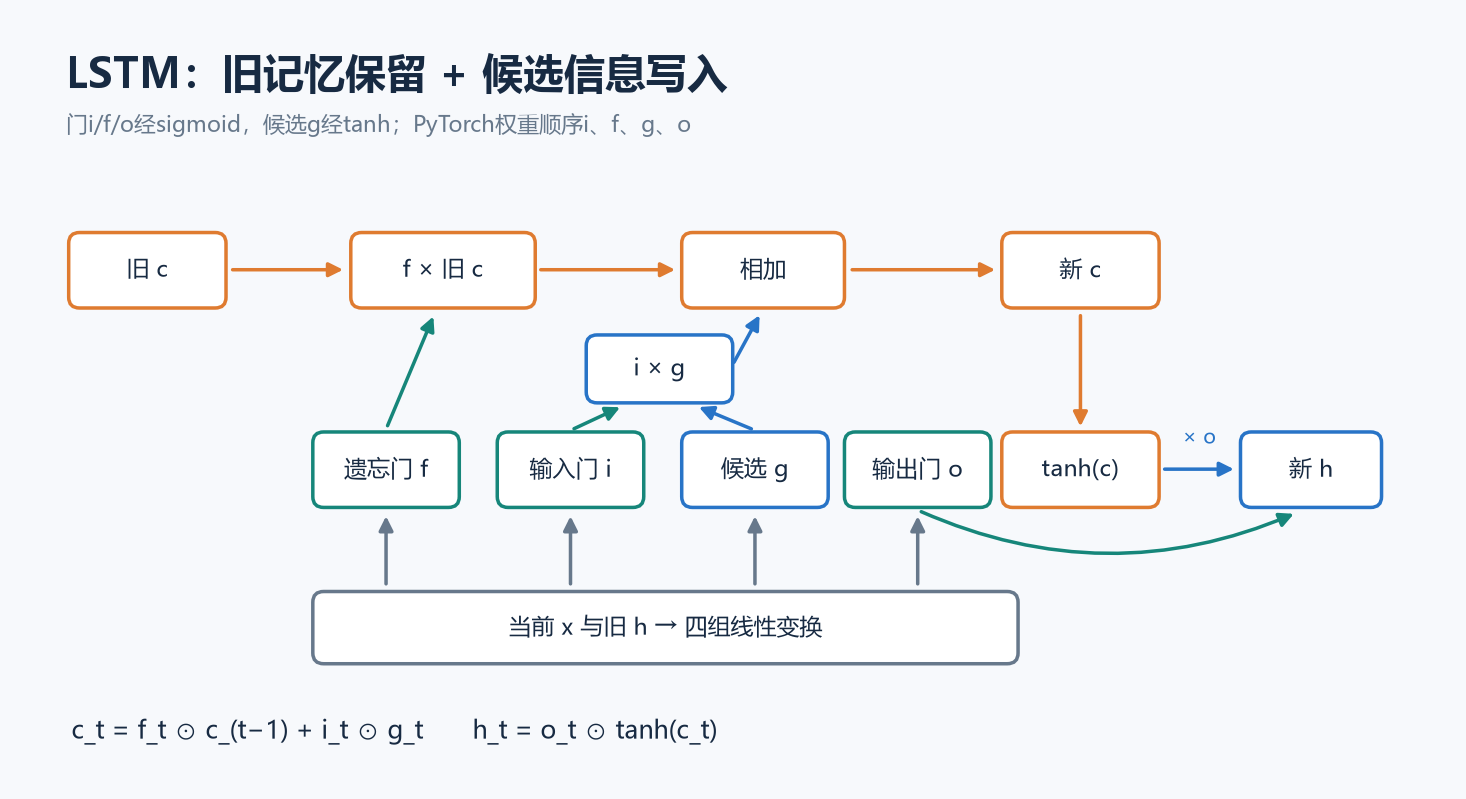

| 项 | 含义 | 容易混淆的地方 |
| --- | --- | --- |
| f，遗忘门 | 控制旧c保留程度 | 接近1表示保留较多；不是删除某个词的指令 |
| i，输入门 | 控制候选信息写入程度 | 控制的是向量各分量，不直接决定句子长度 |
| g，候选状态 | 提供待写入的新信息 | 使用tanh，通常在-1到1之间 |
| o，输出门 | 控制c向h暴露程度 | 不等于类别概率或词表Softmax |
| c，细胞状态 | 累积信息通路 | 不是直接返回的每步output |

符号 $\odot$ 表示逐元素乘法。输入门i、遗忘门f、输出门o不是必须相加为1的三个类别概率；它们由不同参数计算。课件图把门与候选放在流程中，PyTorch权重的实际切分顺序则是 **i、f、g、o**。


## 14. LSTM API：返回output以及(hn, cn)

```python
lstm = nn.LSTM(I, H, num_layers=2, batch_first=True)
lstm_h0 = torch.zeros(2, B, H)
lstm_c0 = torch.zeros(2, B, H)
lstm_output, (lstm_hn, lstm_cn) = lstm(x_batch, (lstm_h0, lstm_c0))
assert lstm_output.shape == (B, T, H)
assert lstm_hn.shape == lstm_cn.shape == (2, B, H)
torch.testing.assert_close(lstm_output[:, -1], lstm_hn[-1])
print("LSTM output/hn/cn:", tuple(lstm_output.shape),
      tuple(lstm_hn.shape), tuple(lstm_cn.shape))
```

常见错误是写成`output, hn = lstm(...)`后继续把hn当张量：此时第二项实际是`(hn, cn)`二元组。`output`对应h，不包含每个时间步的c。

本篇无projection。若使用`proj_size`，h与c的末维有不同定义，要重新查API；不能把这里的同shape结论照搬。


## 15. 拆开LSTMCell权重，核对四组计算

`nn.LSTM`处理整段序列，`nn.LSTMCell`处理一步。下面仅核对一个时间步，没有训练或推断类别。

```python
lstm_cell = nn.LSTMCell(I, H).double()
cell_x = torch.randn(B, I, dtype=torch.float64)
cell_prev_h = torch.randn(B, H, dtype=torch.float64)
cell_prev_c = torch.randn(B, H, dtype=torch.float64)
with torch.no_grad():
    api_h, api_c = lstm_cell(cell_x, (cell_prev_h, cell_prev_c))
    gate_values = (cell_x @ lstm_cell.weight_ih.T + lstm_cell.bias_ih
                   + cell_prev_h @ lstm_cell.weight_hh.T + lstm_cell.bias_hh)
    raw_i, raw_f, raw_g, raw_o = gate_values.chunk(4, dim=1)
    gate_i, gate_f = raw_i.sigmoid(), raw_f.sigmoid()
    candidate_g, gate_o = raw_g.tanh(), raw_o.sigmoid()
    hand_c = gate_f * cell_prev_c + gate_i * candidate_g
    hand_h = gate_o * hand_c.tanh()
    torch.testing.assert_close(hand_h, api_h, rtol=1e-10, atol=1e-10)
    torch.testing.assert_close(hand_c, api_c, rtol=1e-10, atol=1e-10)
    lstm_manual_error = max((hand_h-api_h).abs().max().item(),
                            (hand_c-api_c).abs().max().item())
print("LSTM一步最大误差:", lstm_manual_error)
```

一次线性计算得到`4*H`维，再切为四组，是门计算的向量化写法。把i/f/g/o的顺序写错，即使shape都对，也会得到错误的状态递推。


## 16. Bi-LSTM：两个方向的最终状态在哪里

双向LSTM让同一位置同时利用前面与后面的上下文。最后一维通常拼接“正向表示、反向表示”，维数为`2*H`。这种结构适合整段输入已知的编码；要求不偷看未来的逐步生成不能直接采用同一双向输入处理方式。

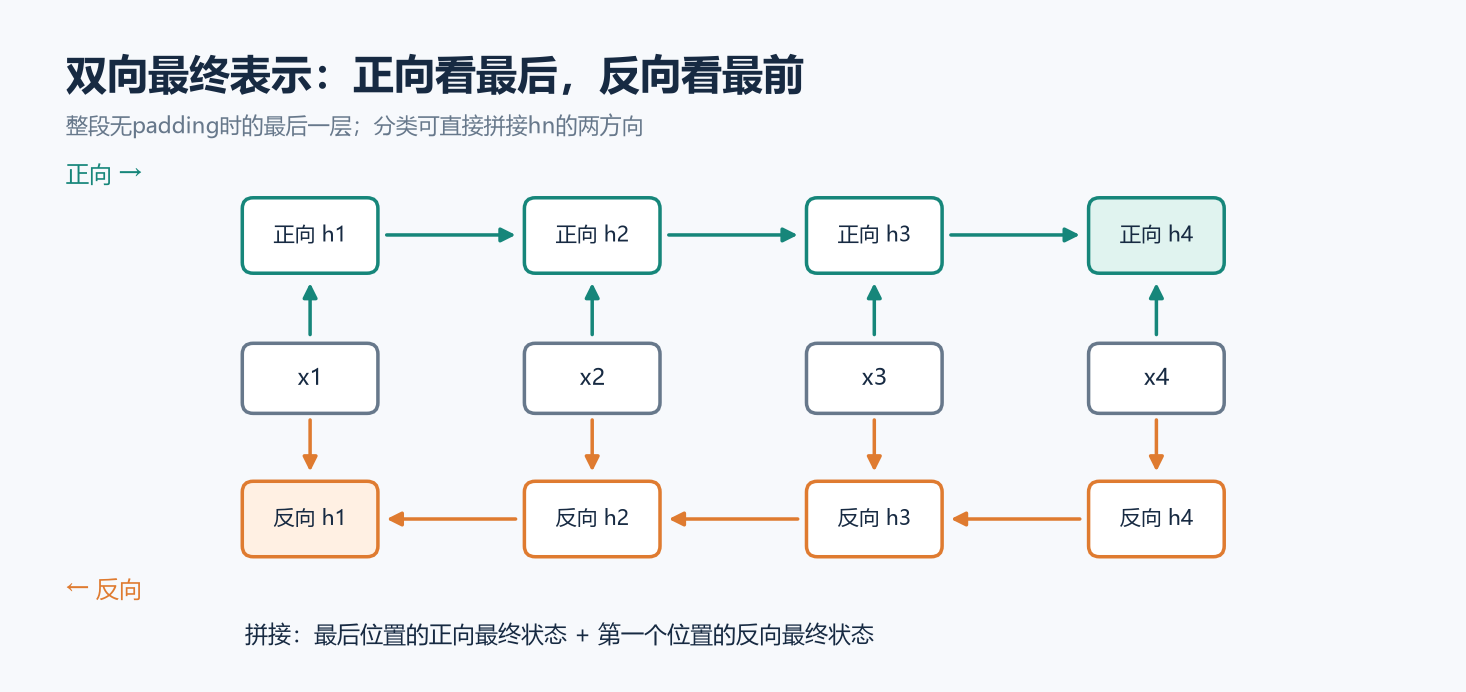

对于无padding的完整序列：正向最终状态在最后位置，反向最终状态在**第一个位置**。因此把`output[:, -1]`直接用于双向分类，只取到了最后位置的反向表示，而不是反向读完整个序列后的状态。

```python
bi_lstm = nn.LSTM(I, H, num_layers=2, bidirectional=True, batch_first=True)
bi_output, (bi_hn, bi_cn) = bi_lstm(x_batch)
assert bi_output.shape == (B, T, 2 * H)
assert bi_hn.shape == bi_cn.shape == (2 * 2, B, H)
bi_h_by_layer = bi_hn.reshape(2, 2, B, H)  # 层、方向、batch、H
final_forward = bi_h_by_layer[-1, 0]
final_backward = bi_h_by_layer[-1, 1]
bi_sequence_features = torch.cat([final_forward, final_backward], dim=-1)
torch.testing.assert_close(bi_output[:, -1, :H], final_forward)
torch.testing.assert_close(bi_output[:, 0, H:], final_backward)
assert bi_sequence_features.shape == (B, 2 * H)
print("双向output/hn/分类前表示:", tuple(bi_output.shape),
      tuple(bi_hn.shape), tuple(bi_sequence_features.shape))
```

hn顺序是第0层正向、第0层反向、第1层正向、第1层反向……；最后一层的两方向要成对取出。若序列有padding，还应先正确处理有效长度。双向通常增加参数与计算，多层时后续层输入维变为2H，不能无条件说“总参数正好是单向两倍”。


## 17. GRU：两个门，没有独立的c

GRU（Gated Recurrent Unit，门控循环单元）用重置门r和更新门z控制状态，只有隐藏状态h。下列公式采用**PyTorch约定**，候选写作n：

$$
\begin{aligned}
r_t &= \sigma(W_{ir}x_t+b_{ir}+W_{hr}h_{t-1}+b_{hr}),\\
z_t &= \sigma(W_{iz}x_t+b_{iz}+W_{hz}h_{t-1}+b_{hz}),\\
n_t &= \tanh\!\left(W_{in}x_t+b_{in}+r_t\odot(W_{hn}h_{t-1}+b_{hn})\right),\\
h_t &= (1-z_t)\odot n_t+z_t\odot h_{t-1}.
\end{aligned}
$$

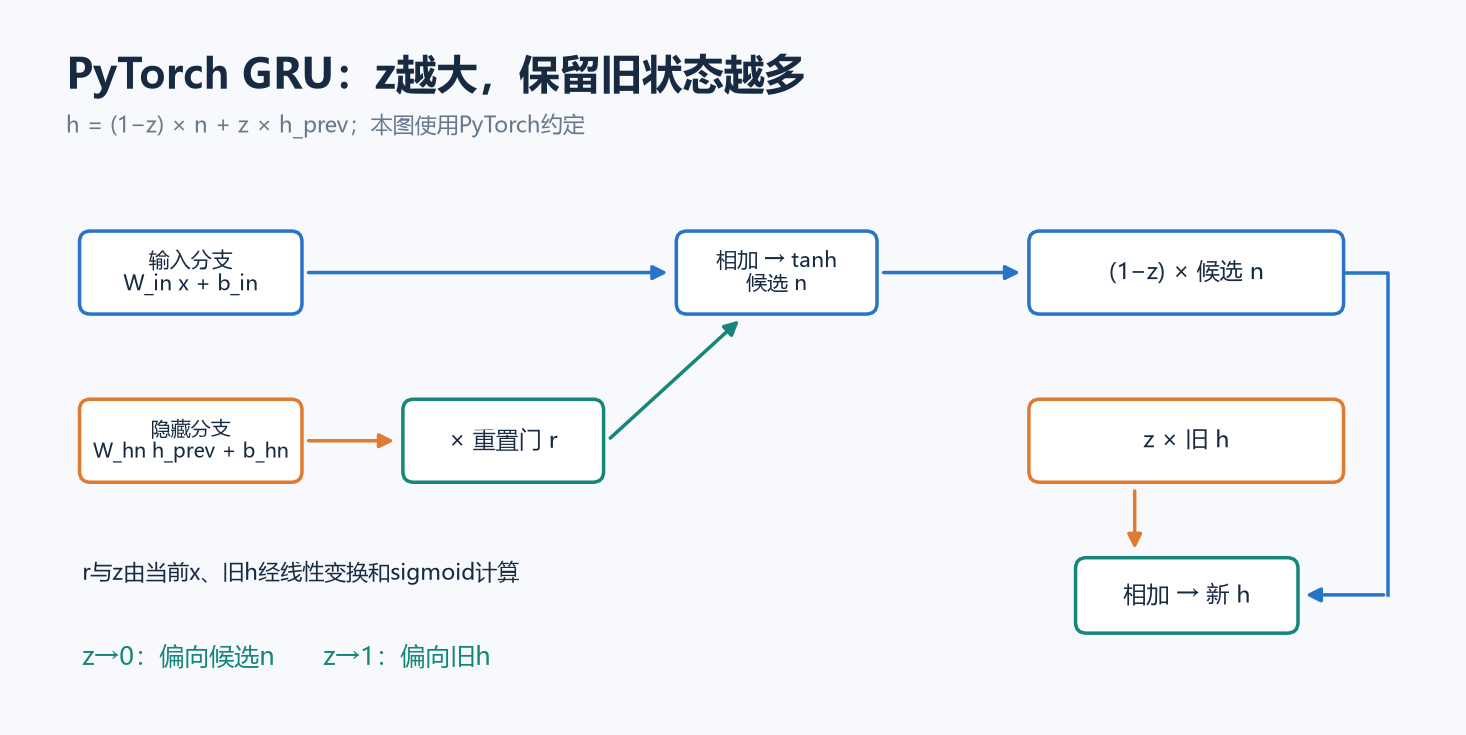

**课件与PyTorch的z方向不同。** 课件写成`(1-z)*旧状态 + z*候选状态`，z大时偏向新信息；PyTorch写成`(1-z)*候选状态 + z*旧状态`，z大时偏向保留旧信息。解释门的意义必须先看所用公式。

| PyTorch z | 更新结果趋向 |
| --- | --- |
| 接近0 | 候选n |
| 接近1 | 旧状态h_prev |

另外，PyTorch把r乘在隐藏状态的线性变换**之后**，包括该分支bias；某些教材把r先乘h再做矩阵变换。矩阵乘法与逐元素门控一般不可随意交换，这两种候选公式不能直接拿来逐数值核对。


## 18. GRU API与手算核对

```python
gru = nn.GRU(I, H, num_layers=2, batch_first=True)
gru_output, gru_hn = gru(x_batch)
assert gru_output.shape == (B, T, H)
assert gru_hn.shape == (2, B, H)
torch.testing.assert_close(gru_output[:, -1], gru_hn[-1])

gru_cell = nn.GRUCell(I, H).double()
with torch.no_grad():
    gru_api_h = gru_cell(cell_x, cell_prev_h)
    from_x = cell_x @ gru_cell.weight_ih.T + gru_cell.bias_ih
    from_h = cell_prev_h @ gru_cell.weight_hh.T + gru_cell.bias_hh
    xr, xz, xn = from_x.chunk(3, dim=1)  # PyTorch顺序r、z、n
    hr, hz, hn_linear = from_h.chunk(3, dim=1)
    reset_r = (xr + hr).sigmoid()
    update_z = (xz + hz).sigmoid()
    candidate_n = (xn + reset_r * hn_linear).tanh()
    gru_hand_h = (1 - update_z) * candidate_n + update_z * cell_prev_h
    torch.testing.assert_close(gru_hand_h, gru_api_h, rtol=1e-10, atol=1e-10)
    z_zero, z_one = torch.zeros_like(update_z), torch.ones_like(update_z)
    torch.testing.assert_close((1-z_zero)*candidate_n + z_zero*cell_prev_h, candidate_n)
    torch.testing.assert_close((1-z_one)*candidate_n + z_one*cell_prev_h, cell_prev_h)
    gru_manual_error = (gru_hand_h - gru_api_h).abs().max().item()
print("GRU output/hn:", tuple(gru_output.shape), tuple(gru_hn.shape))
print("GRU一步最大误差:", gru_manual_error)
```

GRU的返回值是`output, hn`，没有cn；门参数切分顺序是r/z/n。它在相同输入、隐藏维下通常比LSTM参数少，但不代表在所有任务上更快、更准确或更适合。


## 19. RNN、LSTM、GRU：只在可比配置下比较参数

对于单层单向、启用bias、无projection的PyTorch实现，每组门有输入权重、循环权重和两组bias：

$$
P_{\text{one group}}=HI+H^2+2H.
$$

普通RNN有1组，GRU有3组，LSTM有4组。这只是当前配置的参数公式，不含Embedding、分类头和优化器状态。

```python
parameter_models = {
    "RNN": nn.RNN(I, H),
    "LSTM": nn.LSTM(I, H),
    "GRU": nn.GRU(I, H),
}
parameter_counts = {name: sum(p.numel() for p in model.parameters())
                    for name, model in parameter_models.items()}
one_group = H * I + H * H + 2 * H
assert parameter_counts == {"RNN": one_group, "LSTM": 4*one_group, "GRU": 3*one_group}
uni_2layer = nn.LSTM(I, H, num_layers=2)
bi_2layer = nn.LSTM(I, H, num_layers=2, bidirectional=True)
uni_count = sum(p.numel() for p in uni_2layer.parameters())
bi_count = sum(p.numel() for p in bi_2layer.parameters())
assert bi_count > 2 * uni_count
print("I=3,H=6,单层单向:", parameter_counts)
print("2层LSTM 单向/双向参数:", uni_count, bi_count)
```

| 模型 | 状态 | 主要特点 | 选择时需要验证 |
| --- | --- | --- | --- |
| RNN | h | 结构简单，便于理解递推 | 长依赖、训练稳定性、准确率 |
| LSTM | h、c | 三个门及候选，显式细胞状态 | 参数与时间成本、泛化效果 |
| GRU | h | 两个门及候选，较简洁 | 是否在当前任务中保持效果 |
| 双向变体 | 每方向各自状态 | 同时编码前后上下文 | 是否允许使用未来输入 |

公平比较要固定划分、输入表示与评估方式，并说明是相同H还是相同参数预算。本篇没有训练这三个分类器，参数量不是准确率的替代指标。


## 20. 人名分类：先把任务和数据契约写清楚

课程案例把人名按**字符序列**输入模型，预测数据集中的来源类别，是N→1分类。若把整个姓氏当作单个词，本例每条往往只剩一个时间步，难以利用字母组合与后缀结构。

课件描述原文件为 `name_classfication.txt`（保持课件拼写），每行是 `人名\t类别`，共20074条、18类。**这些数量来自课件说明，本篇未读取原文件，因此没有验证原数据总数、分布或原实验成绩。**

名字不能确定现实人物的国籍、地区或身份。这里的标签是数据集的关联类别；实际业务不应据此自动限定用户地区或手机号规则。本篇小样本仅学习编码和数据加载接口。

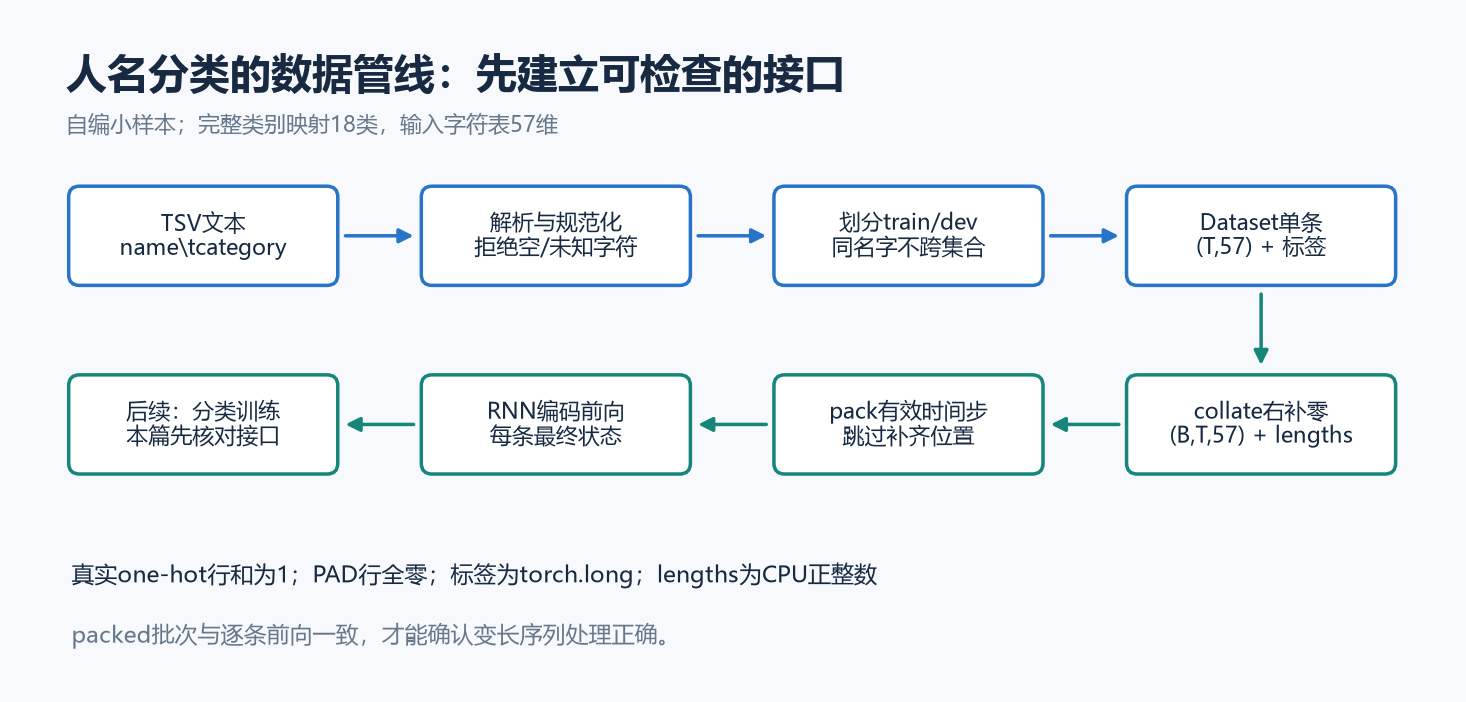

接口契约：

1. 读入与解析：得到`(规范化名字, 类别ID)`。
2. Dataset：一条名字变成`(T,57)`字符one-hot，标签为long标量。
3. DataLoader：batch=1时直接堆叠；更大batch通过collate右补零并返回lengths。
4. RNN前向：需要跳过补齐步时打包序列，拿到每条真实序列的最终状态。


## 21. 固定57字符表与18类别的顺序

课件字符表是52个英文字母加5个符号，**保留大小写差异**：

```python
ALL_LETTERS = string.ascii_letters + " .,;'"
CATEGORIES = [
    "Italian", "English", "Arabic", "Spanish", "Scottish", "Irish",
    "Chinese", "Vietnamese", "Japanese", "French", "Greek", "Dutch",
    "Korean", "Polish", "Portuguese", "Russian", "Czech", "German",
]
LETTER_TO_ID = {letter: index for index, letter in enumerate(ALL_LETTERS)}
CATEGORY_TO_ID = {category: index for index, category in enumerate(CATEGORIES)}
N_LETTERS, N_CATEGORIES = len(ALL_LETTERS), len(CATEGORIES)
assert N_LETTERS == 57 and N_CATEGORIES == 18
assert len(LETTER_TO_ID) == N_LETTERS and len(CATEGORY_TO_ID) == N_CATEGORIES
assert ALL_LETTERS[:26] == string.ascii_lowercase
assert LETTER_TO_ID["a"] != LETTER_TO_ID["A"]
print("字符数/类别数:", N_LETTERS, N_CATEGORIES)
print("Chinese类别ID:", CATEGORY_TO_ID["Chinese"])
```

**one-hot的第0列是字母a，不是PAD。** 本篇用全零向量作为补齐行，用lengths识别有效位置；不要把前面token-ID示例的`0=PAD`直接套到字符one-hot的列索引。

课件用`all_letters.find(letter)`查索引，未找到时返回-1。若把-1直接用于赋值，会悄悄把未知字符写到最后一列，错误冒充撇号。这里采用字典查找，并明确拒绝不支持的字符。


## 22. TSV解析与规范化：不要静默丢失字符

本篇选择：去掉字段边缘空白，NFD分解后去掉组合重音，保留大小写，拒绝剩余未知字符和空名字。例如`Émile→Emile`；`李`仍不在57字符表中，会明确报错。

去重音是**有损策略**，可能把原本不同的名字合并；实际任务可以扩充字符表或引入UNK。训练、验证、预测必须用同一策略。本篇不静默删掉其他不支持的字符，不把`Ł`等字符自动猜成另一个字母。

以下12条TSV完全为自编教学样例，只覆盖Italian、English、Chinese三个标签，保留完整18类映射。它不代表课程数据的分布。

```python
def normalize_name(raw_name):
    if not isinstance(raw_name, str):
        raise TypeError("名字必须为字符串")
    text = raw_name.strip()
    text = "".join(ch for ch in unicodedata.normalize("NFD", text)
                   if unicodedata.category(ch) != "Mn")
    if not text:
        raise ValueError("名字不能为空")
    unknown = sorted(set(text) - set(LETTER_TO_ID))
    if unknown:
        raise ValueError(f"字符表不支持: {unknown!r}")
    return text

def parse_name_tsv(text):
    records = []
    for line_number, line in enumerate(text.splitlines(), start=1):
        if not line.strip():
            continue
        fields = line.split("\t")
        if len(fields) != 2:
            raise ValueError(f"第{line_number}行必须恰好包含两个Tab分隔字段")
        raw_name, category = fields
        category = category.strip()
        if category not in CATEGORY_TO_ID:
            raise ValueError(f"第{line_number}行的类别未知: {category!r}")
        records.append((normalize_name(raw_name), CATEGORY_TO_ID[category]))
    if not records:
        raise ValueError("没有有效记录")
    return records

toy_tsv = "\n".join([
    "Rossi\tItalian", "Bianchi\tItalian", "Moretti\tItalian", "Romano\tItalian",
    "Smith\tEnglish", "Brown\tEnglish", "Jones\tEnglish", "Taylor\tEnglish",
    "Wang\tChinese", "Li\tChinese", "Chen\tChinese", "Zhang\tChinese",
])
with tempfile.TemporaryDirectory(prefix="nlp03-names-") as temporary_directory:
    sample_path = Path(temporary_directory) / "toy_names.tsv"
    sample_path.write_text(toy_tsv, encoding="utf-8")
    all_records = parse_name_tsv(sample_path.read_text(encoding="utf-8"))
assert len(all_records) == 12
assert normalize_name(" Émile ") == "Emile"
assert normalize_name(normalize_name("Émile")) == "Emile"
for invalid_tsv in ("NoTab English", "Wang\tUnknown", "李\tChinese", " \tEnglish"):
    try:
        parse_name_tsv(invalid_tsv)
    except ValueError:
        pass
    else:
        raise AssertionError("应拒绝无效样本")
print("教学样本数:", len(all_records))
print("分布:", {CATEGORIES[k]: v for k, v in Counter(y for _, y in all_records).items()})
```

原文件可以使用同一解析函数读取，但必须先核对编码、分隔符与字符范围。没有Tab的行不能直接用任意空格切分，因为名字字段本身可能包含空格。


## 23. 划分先于Dataset与数据增强

同一规范化名字不要同时出现于训练与验证。课程原数据可能有重复、多来源或同名不同类别，实际应制定分组与歧义处理规则；本篇仅对没有重复的12条样例按类固定留出1条，用来演示两个加载器。

```python
def split_toy_records(records, seed=2026):
    names = [name for name, _ in records]
    if len(names) != len(set(names)):
        raise ValueError("教学划分要求规范化名字唯一；真实数据请按组划分")
    grouped = defaultdict(list)
    for record in records:
        grouped[record[1]].append(record)
    rng = np.random.default_rng(seed)
    train_records, dev_records = [], []
    for label in sorted(grouped):
        group = grouped[label]
        if len(group) < 2:
            raise ValueError("每个演示类别至少要2条")
        order = rng.permutation(len(group))
        dev_records.append(group[int(order[0])])
        train_records.extend(group[int(index)] for index in order[1:])
    return train_records, dev_records

train_records, dev_records = split_toy_records(all_records)
assert len(train_records) == 9 and len(dev_records) == 3
assert {n for n, _ in train_records}.isdisjoint({n for n, _ in dev_records})
assert split_toy_records(all_records) == (train_records, dev_records)
print("train/dev:", len(train_records), len(dev_records))
print("train长度:", [len(name) for name, _ in train_records])
```

只覆盖3类、每类极少样本的留出集没有可靠的模型效果评估价值。完整任务需要足够样本、独立测试集、训练集统计与合适指标。本篇的18类顺序是事先固定的任务配置，不是从验证集学习词表。


## 24. Dataset：一条名字转成(T,57)和long标签

```python
def name_to_onehot(raw_name):
    name = normalize_name(raw_name)
    ids = torch.tensor([LETTER_TO_ID[ch] for ch in name], dtype=torch.long)
    return torch.nn.functional.one_hot(ids, num_classes=N_LETTERS).to(torch.float32)

class NameDataset(Dataset):
    def __init__(self, records):
        self.records = []
        for name, label in records:
            if isinstance(label, bool) or not isinstance(label, numbers.Integral):
                raise ValueError("类别ID必须为整数")
            if not 0 <= int(label) < N_CATEGORIES:
                raise ValueError("类别ID越界")
            self.records.append((normalize_name(name), int(label)))

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        name, label = self.records[index]
        return name_to_onehot(name), torch.tensor(label, dtype=torch.long)

train_dataset = NameDataset(train_records)
dev_dataset = NameDataset(dev_records)
name_tensor, name_label = train_dataset[0]
assert name_tensor.shape == (len(train_records[0][0]), 57)
assert name_tensor.dtype == torch.float32 and name_label.dtype == torch.long
torch.testing.assert_close(name_tensor.sum(dim=1), torch.ones(name_tensor.shape[0]))
recovered_name = "".join(ALL_LETTERS[i] for i in name_tensor.argmax(dim=1).tolist())
assert recovered_name == train_records[0][0]
try:
    name_to_onehot("Li🙂")
except ValueError:
    unknown_character_rejected = True
else:
    raise AssertionError("未知字符不应编码到最后一列")
print("样本:", recovered_name, "shape:", tuple(name_tensor.shape),
      "label:", name_label.item(), CATEGORIES[name_label.item()])
```

Dataset规定取单条数据的方法；DataLoader决定如何采样、批量拼接。`__len__`是样本数，不是字母数；`__getitem__`返回的是第index条名字，而不是名字里的第index个字符。

字符one-hot容易理解，但57维稀疏表示并不是所有NLP任务的最佳方案。若改为字符ID+Embedding，须重新约定PAD/UNK的ID与输入特征维I，不能保留所有旧shape假设。


## 25. DataLoader基础：batch_size=1为何可以直接运行

课件使用batch_size=1，默认collate把`(T,57)`堆成`(1,T,57)`，把标量标签堆成`(1,)`。批次间T可以不同，单个批次没有两条不同长度的张量需要堆叠。

```python
single_loader = DataLoader(train_dataset, batch_size=1, shuffle=False, num_workers=0)
single_x, single_y = next(iter(single_loader))
assert single_x.shape == (1, len(train_records[0][0]), N_LETTERS)
assert single_y.shape == (1,) and single_y.dtype == torch.long
print("batch=1 input/label:", tuple(single_x.shape), tuple(single_y.shape))

# 默认collate无法把长度2和4的两个张量直接stack。
unequal_dataset = NameDataset([("Li", CATEGORY_TO_ID["Chinese"]),
                              ("Wang", CATEGORY_TO_ID["Chinese"])])
try:
    next(iter(DataLoader(unequal_dataset, batch_size=2, num_workers=0)))
except RuntimeError:
    unequal_default_batch_rejected = True
else:
    raise AssertionError("不同长度应触发默认堆叠错误")
```

在Windows Notebook中，教学示例先用`num_workers=0`避免多进程导入与入口管理问题。更大worker数量的性能优化要结合脚本入口、数据量与运行环境测试。


## 26. 自定义collate：右补齐并保留真实长度

```python
def collate_names(batch):
    if not batch:
        raise ValueError("batch不能为空")
    sequences, labels = zip(*batch)
    for seq in sequences:
        if seq.ndim != 2 or seq.shape[0] == 0 or seq.shape[1] != N_LETTERS:
            raise ValueError("每条序列必须为非空(T,57)")
    lengths = torch.tensor([seq.shape[0] for seq in sequences], dtype=torch.long)
    padded = pad_sequence(sequences, batch_first=True, padding_value=0.0)
    labels = torch.stack(labels)
    valid_mask = torch.arange(padded.shape[1])[None, :] < lengths[:, None]
    return padded, lengths, valid_mask, labels

train_generator = torch.Generator().manual_seed(2026)
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True,
                          generator=train_generator, collate_fn=collate_names, num_workers=0)
dev_loader = DataLoader(dev_dataset, batch_size=4, shuffle=False,
                        collate_fn=collate_names, num_workers=0)
batch_x, batch_lengths, batch_mask, batch_y = next(iter(train_loader))
assert batch_x.shape == (len(batch_y), int(batch_lengths.max()), N_LETTERS)
assert batch_lengths.device.type == "cpu" and batch_lengths.dtype == torch.long
assert batch_y.dtype == torch.long and batch_y.ndim == 1
torch.testing.assert_close(batch_x.sum(dim=-1), batch_mask.float())
assert torch.all(batch_x[~batch_mask] == 0)
assert torch.equal(batch_mask.sum(dim=1), batch_lengths)
assert sum(len(labels) for _, _, _, labels in dev_loader) == len(dev_dataset)
print("批input:", tuple(batch_x.shape), "长度:", batch_lengths.tolist())
print("标签:", batch_y.tolist(), "补齐位置数:", (~batch_mask).sum().item())
```

训练一般shuffle=True，验证shuffle=False。generator的状态会随迭代前进，固定初始化种子不表示每个epoch的顺序都完全相同。

本例mask便于检查与后续使用；普通`nn.RNN`并不接受这个mask并自动忽略PAD。即使输入全零，循环权重和bias仍可改变状态，因此不能把补齐后的hn无条件当作真实末尾状态。


## 27. Packed sequence：让RNN只处理有效时间步

PyTorch的`pack_padded_sequence`把右补齐批次按真实长度打包；lengths必须为CPU正整数，并且不超过T。`enforce_sorted=False`允许传入未按长度排序的样本，内部处理排序，最终hn恢复原批次顺序。

下例是一个**没有训练的RNN编码器**。通过逐条无padding前向作参考，证明packed批处理取到的最终状态确实对应原序列，而非只验证shape。

```python
probe_records = [("Li", CATEGORY_TO_ID["Chinese"]),
                 ("Bianchi", CATEGORY_TO_ID["Italian"]),
                 ("Wang", CATEGORY_TO_ID["Chinese"])]
probe_dataset = NameDataset(probe_records)
probe_x, probe_lengths, probe_mask, probe_y = collate_names(
    [probe_dataset[index] for index in range(len(probe_dataset))]
)
name_encoder = nn.RNN(N_LETTERS, 8, batch_first=True).double().eval()
with torch.no_grad():
    packed_x = pack_padded_sequence(probe_x.double(), probe_lengths.cpu(),
                                     batch_first=True, enforce_sorted=False)
    packed_output, packed_hn = name_encoder(packed_x)
    unpacked_output, unpacked_lengths = pad_packed_sequence(packed_output, batch_first=True)
    individual_finals = []
    for index, length in enumerate(probe_lengths.tolist()):
        one_out, one_hn = name_encoder(probe_x[index:index+1, :length].double())
        individual_finals.append(one_hn[0, 0])
        torch.testing.assert_close(unpacked_output[index, :length], one_out[0],
                                   rtol=1e-10, atol=1e-10)
    individual_finals = torch.stack(individual_finals)
    torch.testing.assert_close(packed_hn[-1], individual_finals, rtol=1e-10, atol=1e-10)
    assert torch.equal(unpacked_lengths, probe_lengths)
    assert packed_x.data.shape[0] == int(probe_lengths.sum())
    assert torch.all(unpacked_output[~probe_mask] == 0)

    padded_output, padded_hn = name_encoder(probe_x.double())
    true_end_indices = probe_lengths - 1
    true_end_from_output = padded_output[torch.arange(len(probe_records)), true_end_indices]
    torch.testing.assert_close(true_end_from_output, individual_finals, rtol=1e-10, atol=1e-10)
    packed_max_error = (packed_hn[-1] - individual_finals).abs().max().item()
    padded_final_differences = (padded_hn[-1] - individual_finals).abs().amax(dim=1)
    assert padded_final_differences[0].item() > 1e-8
    torch.testing.assert_close(padded_hn[-1, 1], individual_finals[1])
print("真实长度:", probe_lengths.tolist(), "packed有效步数:", packed_x.data.shape[0])
print("packed与单条最终状态最大误差:", packed_max_error)
print("直接padding后的hn差异:", padded_final_differences.tolist())
```

这里单向RNN处理右padding：在原有效时间步，未来的PAD尚未进入递推，因此可以从output按`length-1`取正确表示；直接取hn则已经处理了补齐步。**该取索引办法不能照搬到双向RNN**，反向计算可能先遇到补齐内容；变长双向编码更应使用正确的packing或其他长度感知方案。

解包后的补齐位置是`pad_packed_sequence`写入的零，不是模型在PAD位置计算了“零状态”。同理，`nn.Embedding(padding_idx=...)`也不保证后续RNN自动跳过该时间步。


## 28. 保存配置：字符表、类别表与处理规则一起保存

模型权重之外还要保存输入输出解释。字符表顺序变了，one-hot列就变了；类别表顺序变了，同一个类别ID就可能被解释为另一个标签。配置应与模型版本配套。

```python
preprocessing_config = {
    "schema_version": 1,
    "letters": ALL_LETTERS,
    "categories": CATEGORIES,
    "normalization": "strip+NFD-remove-Mn; preserve-case; reject-unknown; reject-empty",
    "input_representation": "character-one-hot-float32",
    "padding": "right-zero-vector",
    "lengths": "after-normalization; positive; CPU-int64-for-packing",
    "batch_first": True,
    "split_seed": 2026,
}
with tempfile.TemporaryDirectory(prefix="nlp03-config-") as temporary_directory:
    config_path = Path(temporary_directory) / "preprocessing.json"
    config_path.write_text(json.dumps(preprocessing_config, ensure_ascii=False, indent=2), encoding="utf-8")
    restored_config = json.loads(config_path.read_text(encoding="utf-8"))
assert restored_config == preprocessing_config
restored_letters = {ch: i for i, ch in enumerate(restored_config["letters"])}
restored_categories = {cat: i for i, cat in enumerate(restored_config["categories"])}
assert restored_letters == LETTER_TO_ID and restored_categories == CATEGORY_TO_ID
print("配置往返恢复成功:", restored_config["schema_version"])
```

本篇没有生成分类模型权重。真实预测时先恢复对应配置，再构建一致的预处理与模型，不能从新数据重新排序类别表。


## 29. 常见误区与排查顺序

| 现象或说法 | 原因与正确处理 |
| --- | --- |
| 课件注释写post，输出却左补零 | 检查实际调用，Keras未显式设置时默认pre/pre |
| 输出shape把T、B混在一起 | 先确认batch_first，再标注每个轴 |
| batch_first=True使hn变成(B,L,H) | hn始终按层/方向、batch、H排列 |
| input_size设为人名长度 | input_size是每步特征维，本例为57 |
| 3层output多了3这个轴 | output只给最后层；hn才有层/方向轴 |
| 整个output就是hn | 单向无padding时只对应最后时间步和最后层状态 |
| LSTM返回的hn没有shape | 第二项是(hn,cn)，需要解包 |
| Bi-LSTM直接用output最后位置 | 反向最终状态在首位置；分类用最后层两方向hn |
| GRU更新门越大越偏向新信息 | 先看约定：PyTorch的z大时保留旧状态 |
| GRU手算与API不同 | 检查r/z/n顺序及r乘在隐藏线性变换后的公式 |
| unknown字符“也能运行” | find返回-1悄悄写错列；应拒绝或显式UNK |
| batch_size增大后stack失败 | 变长样本需自定义collate或其他批次策略 |
| PAD是0，所以RNN会忽略 | 循环状态与bias仍参与，使用长度感知处理 |
| lengths也放到GPU | packing长度张量要放CPU，确保正整数及不超T |
| 跨名字复用上个hn | 把独立样本混成连续流，应该重置各样本状态 |
| 随机前向得出类别准确率结论 | 本篇只核对接口；需要训练、独立评估 |

排查顺序：原字段与标签 → 规范化字符 → one-hot列 → lengths/mask → batch布局 → 方向与层数 → 状态提取 → 分类层和训练。先定位输入契约，再调整模型。


## 30. 练习与参考答案

1. 对`[1,2,3,4,5]`设maxlen=3，pre与post截断分别保留什么？长度1右补齐得到什么？
2. `batch_first=True`、B=8、T=12、I=57、H=16、L=2、双向，input、output、hn的shape分别是什么？
3. T加倍会使RNN参数加倍吗？L增加为什么会增加参数？
4. 为什么不能说“output和hn相同”？单向完整无padding时哪个切片对应？
5. LSTM的c与h是否同一个状态？四组权重按什么顺序切分？
6. 双向模型的反向最终状态在output的哪个位置？为什么output最后位置不够？
7. 按PyTorch GRU公式，z=0和z=1时分别得到什么？r在候选计算的哪个位置使用？
8. 本篇57维one-hot的第0列是什么意思？全零补齐行与它有什么区别？
9. `find()`遇到未知字符返回什么？为什么会悄悄编码错误？
10. batch内长度为2、7、4，packed有效输入共有多少步？解包后的零是计算结果吗？
11. 回译后的句子可否直接继承标签？原句和改写分到不同数据集会怎样？
12. 本篇小样本是否验证了课件20074条人名或模型准确率？

参考答案：

- 1：pre保留`[3,4,5]`，post保留`[1,2,3]`；`[1]`右补齐得到`[1,0,0]`。
- 2：`(8,12,57)`、`(8,12,32)`、`(4,8,16)`；LSTM的cn在无projection时也是`(4,8,16)`。
- 3：不会，时间步共享参数；新层有自己的输入、循环权重和bias。
- 4：output包含全部时间步且只含最后层，hn含各层/方向最终状态；单向完整无padding时`output[:,-1] == hn[-1]`。
- 5：不同，c是细胞状态，h是当前隐藏输出；PyTorch为i/f/g/o。
- 6：无padding完整序列的第一个位置；反向在最后位置才刚开始读取，尚未处理整段。
- 7：z=0得到候选n，z=1得到旧h；r乘在隐藏分支线性变换及其bias之后，再与输入分支相加进tanh。
- 8：第0列是字母a；a行有一个1，PAD行全零，真实长度由lengths表示。
- 9：-1；Python张量负索引指向最后一列，导致未知字符冒充撇号。
- 10：13步；解包补齐处是操作写入的零，并非RNN消费PAD后产生的状态。
- 11：需要检查标签语义；原句与近似改写跨划分会造成信息泄漏。
- 12：没有；数量与18类来自课件，代码仅跑自编样例和前向一致性检查。

实践建议：把collate批大小改成2与5；查看每批padding比例；将name_encoder换成单向LSTM或GRU，分别与逐样本前向核对hn（LSTM再核对cn）；对双向模型用最后层两方向hn组成表示。此阶段先证明数据与状态正确，再进入下一篇训练。


## 31. 速查与day03来源对照

| API / 概念 | 必记 |
| --- | --- |
| truncating / padding | 截断方向与补齐方向分开指定 |
| RNN | `output, hn = model(x, h0)` |
| LSTM | `output, (hn, cn) = model(x, (h0,c0))` |
| GRU | `output, hn = model(x, h0)`；无cn |
| batch_first | 只调整input/output，hn/cn不变 |
| 双向分类表示 | 最后一层正向hn与反向hn拼接 |
| Dataset | `__init__`、`__len__`、`__getitem__` |
| DataLoader | 采样顺序、batch_size、collate_fn、num_workers |
| pad_sequence | 本篇输出(B,T,57)，右补全零 |
| pack_padded_sequence | 正的CPU lengths；enforce_sorted=False支持未排序 |
| pad_packed_sequence | 解包并补齐，返回有效长度 |
| 人名字符映射 | 57维one-hot；未知字符明确拒绝 |
| 配置保存 | 字符表、类别表、规范化、padding、布局一起保存 |

已核对的视频标题（省略`.mp4`扩展名）：

| 序号 | 标题 |
| --- | --- |
| 01 | 文本长度规范_代码实现(掌握) |
| 02 | 回译数据增强法介绍(了解) |
| 03 | RNN模型简介(了解) |
| 04 | RNN的分类介绍(掌握) |
| 05 | RNN的模型结构(理解) |
| 06 | RNN代码_基础版(掌握) |
| 07 | RNN代码_修改句子长度(理解) |
| 08 | RNN代码_修改隐藏层及总结(理解) |
| 09 | LSTM模型_原理图解(上)_理解 |
| 10 | LSTM模型_原理图解(下)_理解 |
| 11 | Bi-LSTM模型_介绍(理解) |
| 12 | LSTM模型_代码实现(掌握) |
| 13 | GRU模型_原理图解(掌握) |
| 14 | GRU模型_代码演示(掌握) |
| 15 | RNN人名分类案例_需求介绍(了解) |
| 16 | RNN人名分类案例_获取全局字母表和国家名(掌握) |
| 17 | RNN人名分类案例_读取数据到内存(掌握) |
| 18 | RNN人名分类案例_构建数据集对象(掌握) |
| 19 | RNN人名分类案例_构建数据加载器对象(掌握) |

**PDF范围：**《03-文本预处理-下》第31–38页用于长度规范与回译；《04-RNN及其变体》第1–46页用于RNN、LSTM、Bi-LSTM与GRU；《05-RNN案例人名分类器》已在线读取1–22页，本篇采用第1–17页的任务、字符表、读取、Dataset、DataLoader，后续模型构建部分不在本篇展开。有关视频进度以day03的19节标题为准，不把整份案例课件都写成本日内容。

**补充核对点：**Keras默认pre/pre；output与hn的切片对应条件；batch_first对hn不生效；双向最终状态的选取；课件与PyTorch的GRU门值约定；未知字符的负索引陷阱；padding不等于自动忽略。

查阅：[Keras pad_sequences](https://www.tensorflow.org/api_docs/python/tf/keras/utils/pad_sequences)、[PyTorch RNN](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html)、[LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html)、[GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html)、[GRUCell](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRUCell.html)、[Dataset与DataLoader](https://docs.pytorch.org/docs/stable/data.html)、[pack_padded_sequence](https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.rnn.pack_padded_sequence.html)。


## 32. 本篇运行核对记录

本篇全部 **20段Python代码**已按阅读顺序在同一命名空间执行，使用CPU：Python 3.12.13、NumPy 1.26.4、PyTorch 2.14.1+cpu。

| 核对项目 | 实际结果 |
| --- | --- |
| pre/pre与post/post | 与正文展示数组一致，四种方向及空序列边界均已检查 |
| RNN手算整段递推 | 最大绝对误差 `5.551e-17`；逐步调用与整段调用一致 |
| LSTMCell四组门公式 | h与c均与API一致，最大绝对误差 `2.776e-17` |
| GRUCell PyTorch公式 | 最大绝对误差 `1.110e-16`，按r/z/n顺序切分 |
| 双向LSTM状态 | 正向最后位置、反向首位置与对应hn一致 |
| 单层单向参数量，I=3/H=6 | RNN=66，LSTM=264，GRU=198 |
| 教学TSV | 12条，train=9/dev=3，只覆盖3类，完整配置18类与57字符 |
| 变长批次 | 长度2/7/4，共13有效步；packed与逐条最终状态最大误差 `1.110e-16` |
| 未处理padding的hn | 短序列与正确最终状态不同；最长序列一致，复现了补齐陷阱 |
| 输入异常与配置 | 非法TSV、未知字符、默认变长堆叠均按预期拒绝；配置JSON可完整恢复 |
| Notebook附件 | 7幅独立绘制PNG，全部直接嵌入，没有外部图片依赖 |

Notebook格式、单元ID和既有52本笔记的内容哈希均已核对。代码中的断言检查的是具体数值、映射与序列行为，未训练分类器、未报告准确率。

这些核对证明本篇示例的公式、接口与序列处理逻辑一致，不证明模型已经获得分类能力。下一篇可在同一字符表、类别表和数据契约上构建分类器、损失及训练过程。

浏览器预览已检查：7幅内嵌图均加载，9处数学表达式正常渲染，没有公式报错或页面横向溢出。
